## Importy i stałe
Biblioteki i ustawienia w jednym miejscu (ścieżki do zbioru oryginalnego i po preprocessingu, nazwy 7 klas, rozmiar obrazu używany przy treningu, ewaluacji i predykcji).

In [2]:
from collections import Counter
from getpass import getpass
from pathlib import Path
import hashlib
import random
import shutil

import cv2
import matplotlib.pyplot as plt
from roboflow import Roboflow
from ultralytics import YOLO

DATASET_DIR = Path("datasets/emotions")
PROCESSED_DIR = Path("datasets/emotions_clahe")
NAMES = ["Angry", "Disgusted", "Fearful", "Happy", "Neutral", "Sad", "Surprised"]
IMGSZ = 96

## Pobranie zbioru
Zbiór (wersja 4) z Roboflow Universe w formacie YOLOv8. Klucz wpisywany przez `getpass`, więc nie trafia do kodu. Komórka wykorzystana jednorazowo, jej zadaniem jest tylko pobranie zbioru.

In [ ]:
rf = Roboflow(api_key=getpass("Roboflow API key: "))
project = rf.workspace("jhazmine-therese-roque-biwst").project("emotion-detection-ooj7h")
dataset = project.version(4).download("yolov8", location=str(DATASET_DIR))

yaml_path = DATASET_DIR / "data.yaml"
yaml_path.write_text(yaml_path.read_text().replace("../", ""))

## Rozkład klas
Liczenie ramki każdej emocji w train, valid i test oraz zdjęcia bez etykiet. Klasy są wyrównane.

train: 4487 boxes, 0 images without boxes
{'Angry': 642, 'Disgusted': 644, 'Fearful': 634, 'Happy': 639, 'Neutral': 640, 'Sad': 640, 'Surprised': 648}
valid: 550 boxes, 0 images without boxes
{'Angry': 79, 'Disgusted': 78, 'Fearful': 83, 'Happy': 73, 'Neutral': 74, 'Sad': 85, 'Surprised': 78}
test: 566 boxes, 0 images without boxes
{'Angry': 80, 'Disgusted': 78, 'Fearful': 83, 'Happy': 91, 'Neutral': 85, 'Sad': 75, 'Surprised': 74}


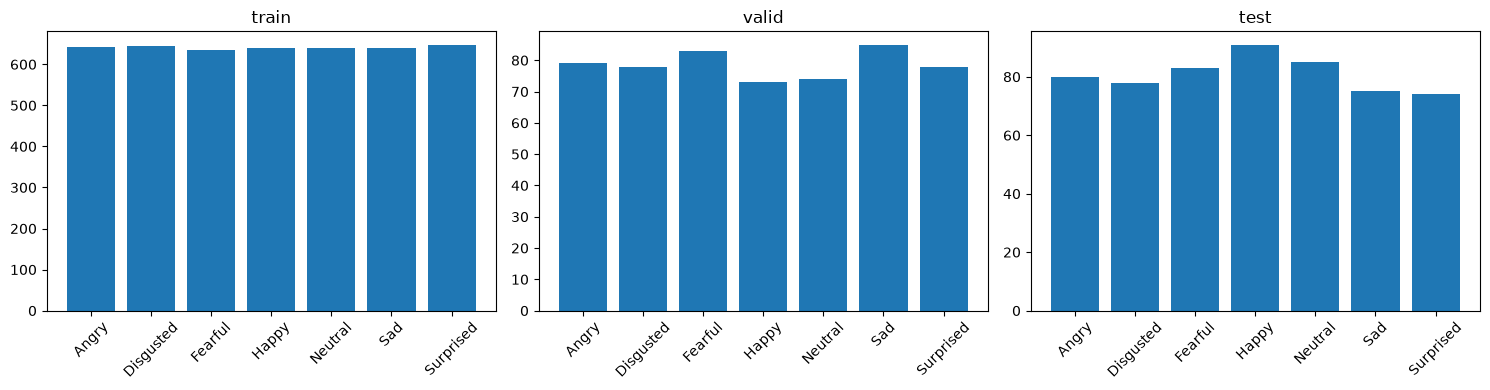

In [3]:
def count_classes(split):
    counts, empty = Counter(), 0
    for f in (DATASET_DIR / split / "labels").glob("*.txt"):
        lines = f.read_text().strip().splitlines()
        if not lines:
            empty += 1
        for line in lines:
            counts[int(line.split()[0])] += 1
    return counts, empty

fig, axes = plt.subplots(1, 3, figsize=(15, 4), sharey=False)
for ax, split in zip(axes, ["train", "valid", "test"]):
    counts, empty = count_classes(split)
    print(f"{split}: {sum(counts.values())} boxes, {empty} images without boxes")
    print({NAMES[i]: counts[i] for i in range(7)})
    ax.bar(NAMES, [counts[i] for i in range(7)])
    ax.set_title(split)
    ax.tick_params(axis="x", rotation=45)
plt.tight_layout()
plt.show()

## Preprocessing
Skala szarości -> rozmycie Gaussa 3x3 (odszumienie) -> CLAHE (lokalna poprawa kontrastu) -> powrót do 3 kanałów (wymagane, bo YOLO oczekuje obrazu z trzema kanałami). Parametry są łagodne ze względu na małe zdjęcia.

In [4]:
def apply_clahe(img):
    gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)
    gray = cv2.GaussianBlur(gray, (3, 3), 0)
    clahe = cv2.createCLAHE(clipLimit=1.5, tileGridSize=(2, 2))
    gray = clahe.apply(gray)
    return cv2.cvtColor(gray, cv2.COLOR_GRAY2BGR)

## Przetworzenie zbioru
Tworzenie kopii zbioru po preprocessingu.

In [5]:
for split in ["train", "valid", "test"]:
    out_images = PROCESSED_DIR / split / "images"
    out_images.mkdir(parents=True, exist_ok=True)

    shutil.copytree(DATASET_DIR / split / "labels",
                    PROCESSED_DIR / split / "labels",
                    dirs_exist_ok=True)

    for path in (DATASET_DIR / split / "images").glob("*.jpg"):
        img = cv2.imread(str(path))
        cv2.imwrite(str(out_images / path.name), apply_clahe(img))

shutil.copy(DATASET_DIR / "data.yaml", PROCESSED_DIR / "data.yaml")
print("Ready")

Ready


## Podgląd przed/po
Trzy losowe zdjęcia przed i po CLAHE.

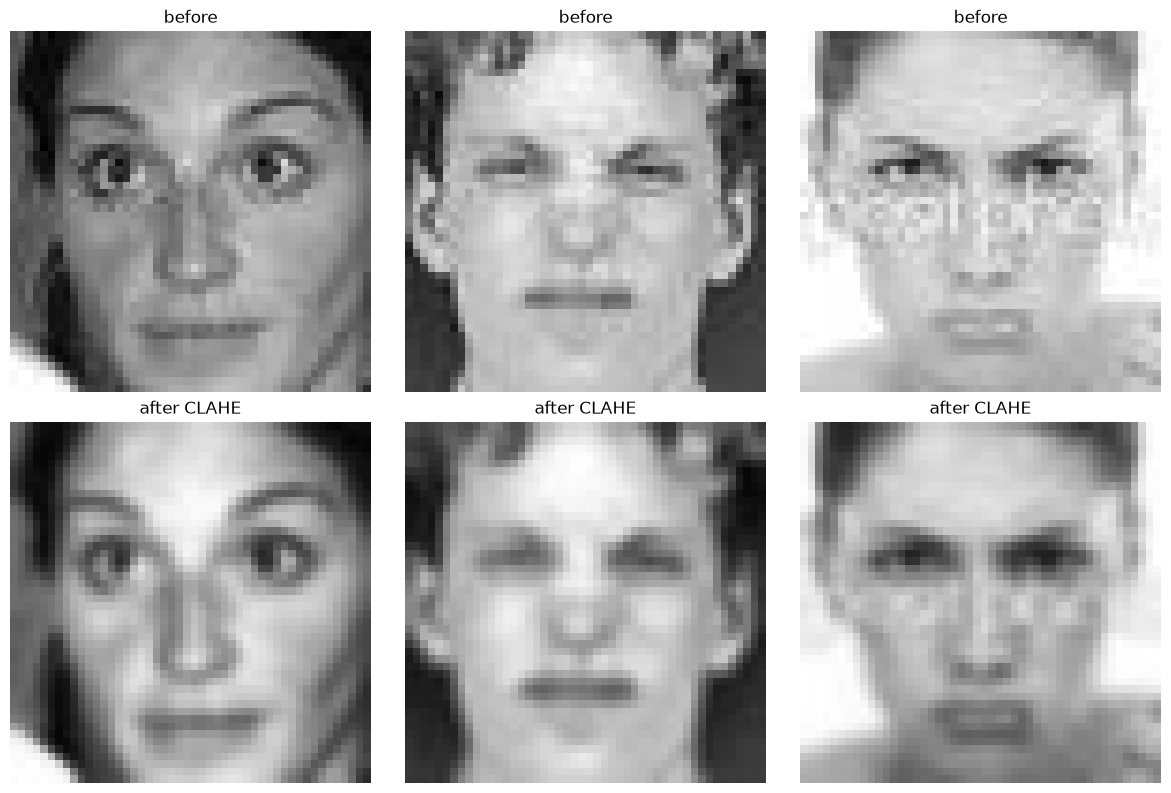

In [6]:
random.seed(42)
files = random.sample(list((DATASET_DIR / "train" / "images").glob("*.jpg")), 3)

fig, axes = plt.subplots(2, 3, figsize=(12, 8))
for i, path in enumerate(files):
    before = cv2.imread(str(path))
    after = cv2.imread(str(PROCESSED_DIR / "train" / "images" / path.name))
    axes[0, i].imshow(cv2.cvtColor(before, cv2.COLOR_BGR2RGB))
    axes[0, i].set_title("before")
    axes[1, i].imshow(cv2.cvtColor(after, cv2.COLOR_BGR2RGB))
    axes[1, i].set_title("after CLAHE")
    axes[0, i].axis("off")
    axes[1, i].axis("off")
plt.tight_layout()
plt.savefig("preprocessing_example.png", dpi=100)
plt.show()

## Ewaluacja na zbiorze testowym
Zbiór testowy nie brał udziału w treningu. Każdy model oceniany na na swojej wersji zbioru (baseline na oryginałach, clahe po preprocessingu).

In [7]:
for name, data in [("baseline", DATASET_DIR / "data.yaml"),
                   ("clahe", PROCESSED_DIR / "data.yaml")]:
    model = YOLO(f"results/{name}/best.pt")
    m = model.val(data=str(data), split="test", imgsz=IMGSZ, device="cpu", name=f"test_{name}")
    print(name, "mAP50:", round(m.box.map50, 3), "mAP50-95:", round(m.box.map, 3),
          "precision:", round(m.box.mp, 3), "recall:", round(m.box.mr, 3))

Ultralytics 8.4.216 🚀 Python-3.14.2 torch-2.15.0+cu132 CPU (AMD EPYC 7763 64-Core Processor)
Model summary (fused): 73 layers, 3,134,165 parameters, 0 gradients, 8.6 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 65.7±15.8 MB/s, size: 1.2 KB)
val: Scanning /workspaces/edu-grafika-lab3/datasets/emotions/test/labels.cache... 566 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 566/566 131.9Mit/s 0.0s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 36/36 6.8it/s 5.3s<0.1s
                   all        566        566      0.472      0.726      0.615       0.59
                 Angry         80         80      0.317      0.625      0.418      0.372
             Disgusted         78         78      0.522      0.923      0.802       0.79
               Fearful         83         83      0.384      0.518      0.418      0.387
                 Happy         91         91      0.728      0.714      0.833       0.82
        

## Własne zdjęcia
Model clahe dostaje zdjęcia przepuszczone przez `apply_clahe`, baseline oryginał. Próg pewności obniżony względem domyślnego 0.25, bo przy nim większość ramek znikała.

test1.jpg baseline Neutral 0.18
test1.jpg clahe Happy 0.24
test2.jpg baseline Happy 0.7
test2.jpg clahe Happy 0.35
test2.jpg clahe Disgusted 0.28
test3.JPG baseline Fearful 0.34
test3.JPG baseline Neutral 0.2
test3.JPG baseline Surprised 0.18
test3.JPG clahe Surprised 0.19
test4.jpeg baseline Happy 0.15
test5.jpeg baseline Happy 0.6


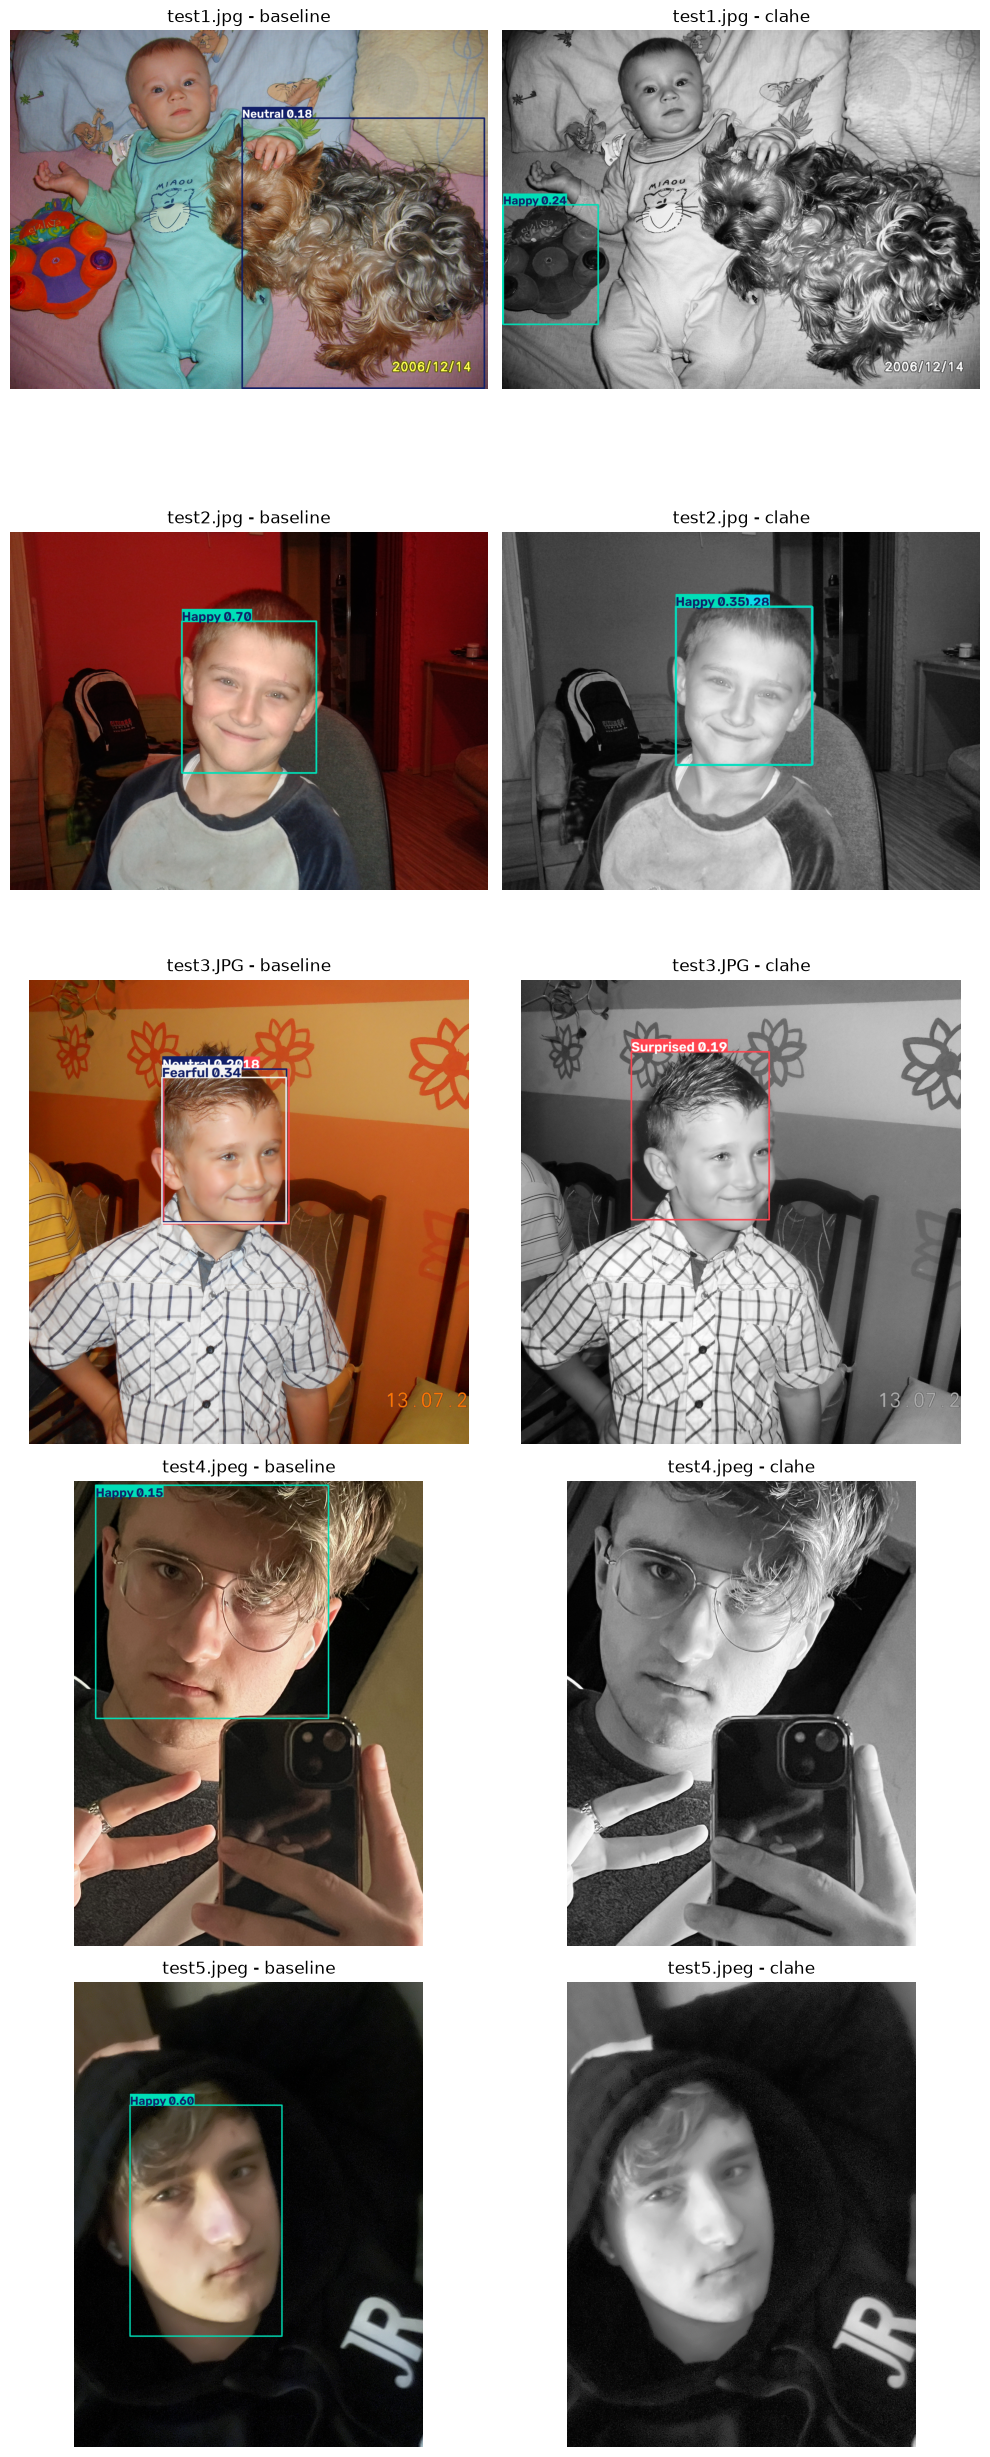

In [8]:
paths = [p for p in sorted(Path("samples").iterdir())
         if p.suffix.lower() in (".jpg", ".jpeg")]

model_b = YOLO("results/baseline/best.pt")
model_c = YOLO("results/clahe/best.pt")

fig, axes = plt.subplots(len(paths), 2, figsize=(10, 5 * len(paths)), squeeze=False)

for row, path in enumerate(paths):
    img = cv2.imread(str(path))
    res_b = model_b.predict(img, imgsz=IMGSZ, conf=0.15, verbose=False)[0]
    res_c = model_c.predict(apply_clahe(img), imgsz=IMGSZ, conf=0.15, verbose=False)[0]

    for col, (res, title) in enumerate([(res_b, "baseline"), (res_c, "clahe")]):
        axes[row, col].imshow(cv2.cvtColor(res.plot(), cv2.COLOR_BGR2RGB))
        axes[row, col].set_title(f"{path.name} - {title}")
        axes[row, col].axis("off")
        for box in res.boxes:
            print(path.name, title, NAMES[int(box.cls)], round(float(box.conf), 2))

plt.tight_layout()
plt.savefig("results/prediction_examples.png", dpi=100)
plt.show()

## Test duplikatów
Porównanie skrótów MD5 plików z train i test: 0 wspólnych. Wykrywa tylko identyczne pliki, komórka tylko w celu sprawdzenia, czy zbiór testowy nie zawiera zdjęć z treningu.

In [9]:
def hashes(split):
    return {hashlib.md5(p.read_bytes()).hexdigest()
            for p in (DATASET_DIR / split / "images").glob("*.jpg")}

print("same photos train/test:", len(hashes("train") & hashes("test")))

same photos train/test: 0


## Czułość na rozmiar wejścia
To samo zdjęcie z `imgsz` 96, 160 i 320 oraz niskim progiem 0,05, żeby sprawdzić, czy wynik zależy od rozmiaru. Wypisuje trzy najlepsze detekcje.

In [10]:
for path in paths:
    img = cv2.imread(str(path))
    for size in [96, 160, 320]:
        for title, model, im in [("baseline", model_b, img), ("clahe", model_c, apply_clahe(img))]:
            res = model.predict(im, imgsz=size, conf=0.05, verbose=False)[0]
            found = [(NAMES[int(b.cls)], round(float(b.conf), 2)) for b in res.boxes]
            print(path.name, size, title, found[:3])

test1.jpg 96 baseline [('Neutral', 0.18), ('Surprised', 0.08)]
test1.jpg 96 clahe [('Happy', 0.24), ('Happy', 0.1), ('Surprised', 0.08)]
test1.jpg 160 baseline [('Surprised', 0.12)]
test1.jpg 160 clahe [('Happy', 0.1), ('Neutral', 0.1), ('Happy', 0.06)]
test1.jpg 320 baseline [('Fearful', 0.31), ('Sad', 0.18), ('Angry', 0.18)]
test1.jpg 320 clahe [('Fearful', 0.59), ('Happy', 0.2), ('Happy', 0.1)]
test2.jpg 96 baseline [('Happy', 0.7)]
test2.jpg 96 clahe [('Happy', 0.35), ('Disgusted', 0.28)]
test2.jpg 160 baseline [('Happy', 0.64), ('Sad', 0.06)]
test2.jpg 160 clahe [('Happy', 0.84), ('Neutral', 0.1), ('Fearful', 0.07)]
test2.jpg 320 baseline [('Happy', 0.7), ('Happy', 0.48), ('Fearful', 0.17)]
test2.jpg 320 clahe [('Happy', 0.65)]
test3.JPG 96 baseline [('Fearful', 0.34), ('Neutral', 0.2), ('Surprised', 0.18)]
test3.JPG 96 clahe [('Surprised', 0.19)]


test3.JPG 160 baseline [('Fearful', 0.16), ('Angry', 0.15), ('Sad', 0.12)]
test3.JPG 160 clahe [('Surprised', 0.06), ('Surprised', 0.06)]
test3.JPG 320 baseline [('Sad', 0.1)]
test3.JPG 320 clahe [('Happy', 0.28)]
test4.jpeg 96 baseline [('Happy', 0.15)]
test4.jpeg 96 clahe []
test4.jpeg 160 baseline [('Happy', 0.2), ('Sad', 0.12)]
test4.jpeg 160 clahe []
test4.jpeg 320 baseline [('Angry', 0.16), ('Neutral', 0.12), ('Happy', 0.08)]
test4.jpeg 320 clahe [('Surprised', 0.17)]
test5.jpeg 96 baseline [('Happy', 0.6), ('Happy', 0.08)]
test5.jpeg 96 clahe [('Angry', 0.12)]
test5.jpeg 160 baseline [('Sad', 0.19)]
test5.jpeg 160 clahe [('Happy', 0.14), ('Happy', 0.06), ('Happy', 0.05)]
test5.jpeg 320 baseline [('Neutral', 0.13), ('Neutral', 0.1), ('Neutral', 0.09)]
test5.jpeg 320 clahe [('Happy', 0.27), ('Happy', 0.22), ('Happy', 0.15)]


## Preprocessing w treningu a przy użyciu
Sprawdzenie wszystkich czterech kombinacji: model (baseline lub clahe) oceniany na zdjęciach oryginalnych i po CLAHE. Pokazuje, czy preprocessing działa jako część modelu, czy da się go dołożyć dopiero przy użyciu.

In [12]:
for train_name in ["baseline", "clahe"]:
    model = YOLO(f"results/{train_name}/best.pt")
    for test_name, data in [("orig", DATASET_DIR / "data.yaml"),
                            ("clahe", PROCESSED_DIR / "data.yaml")]:
        m = model.val(data=str(data), split="test", imgsz=IMGSZ, device="cpu",
                      plots=False, verbose=False)
        print(f"model {train_name} / test {test_name}: "
              f"mAP50 {m.box.map50:.3f}, mAP50-95 {m.box.map:.3f}")

Ultralytics 8.4.216 🚀 Python-3.14.2 torch-2.15.0+cu132 CPU (AMD EPYC 7763 64-Core Processor)


Model summary (fused): 73 layers, 3,134,165 parameters, 0 gradients, 8.6 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 199.8±337.7 MB/s, size: 7.2 KB)
val: Scanning /workspaces/edu-grafika-lab3/datasets/emotions/test/labels.cache... 566 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 566/566 215.8Mit/s 0.0s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 36/36 12.9it/s 2.8s0.2s
                   all        566        566      0.472      0.726      0.615       0.59
Speed: 0.0ms preprocess, 3.6ms inference, 0.0ms loss, 0.3ms postprocess per image
model baseline / test orig: mAP50 0.615, mAP50-95 0.590
Ultralytics 8.4.216 🚀 Python-3.14.2 torch-2.15.0+cu132 CPU (AMD EPYC 7763 64-Core Processor)
Model summary (fused): 73 layers, 3,134,165 parameters, 0 gradients, 8.6 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 81.2±33.0 MB/s, size: 1.6 KB)
val: Scanning /workspaces/edu-grafika-lab3/datasets/emotions_cla